In [28]:
# --- Standard library ---
import os
import re
import json
from collections import defaultdict

# --- Numerical ---
import numpy as np

# --- SVG parsing ---
from svgpathtools import svg2paths2

# --- Geometry ---
from shapely.geometry import Polygon as ShapelyPolygon



# --- Rendering ---
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon  # for rendering ONLY
from matplotlib.collections import PatchCollection
import random
from shapely.affinity import translate


In [73]:
SIZE_ORDER = {
    "XS": 0,
    "S": 1,
    "M": 2,
    "L": 3,
    "XL": 4,
    "XXL": 5,
    "XXXL": 6
}

def size_rank(shape):
    """
    Converts size to a sortable numeric rank.
    Handles numeric and alpha sizes.
    """
    s = str(shape["size"]).upper()

    # Numeric sizes (kidswear, measurements)
    try:
        return int(s)
    except ValueError:
        pass

    # Alpha sizes
    if s in SIZE_ORDER:
        return SIZE_ORDER[s]

    # Fallback: push unknown sizes to the end
    return 999


In [74]:
PART_PRIORITY = {
    "FRONT": 0,
    "BACK": 1,
    "SLEEVE": 2
}
def size_key(shape):
    """
    Converts size to sortable value.
    Falls back gracefully if non-numeric.
    """
    try:
        return int(shape["size"])
    except:
        return shape["size"]
def order_panels_first(shapes):
    """
    Deterministic Strategy D4:
    Panels first, then sleeves, size-descending within part
    """
    def sort_key(s):
        part_rank = PART_PRIORITY.get(s["part"].upper(), 99)
        return (
            part_rank,
            -size_rank(s)
        )

    return sorted(shapes, key=sort_key)


In [66]:
def shape_area(shape):
    """
    shape: dict with key 'polygon' as list of (x, y)
    """
    return ShapelyPolygon(shape["polygon"]).area

def order_by_area_desc(shapes):
    """
    Deterministic Strategy D2:
    Sort shapes by polygon area (descending)
    """
    return sorted(
        shapes,
        key=lambda s: shape_area(s),
        reverse=True
    )

def run_d2_area_desc(shapes, strip_width):
    ordered = order_by_area_desc(shapes)
    placed = phase5_skyline_packer(ordered, strip_width)
    return placed


In [59]:
def skyline_height_at(skyline, x_start, x_end):
    """
    Returns the max skyline height under [x_start, x_end]
    """
    h = 0.0
    for xs, xe, height in skyline:
        if xe <= x_start or xs >= x_end:
            continue
        h = max(h, height)
    return h

def update_skyline(skyline, x_start, x_end, new_height):
    """
    Raises skyline to new_height over [x_start, x_end]
    """
    new_skyline = []

    for xs, xe, h in skyline:
        # No overlap
        if xe <= x_start or xs >= x_end:
            new_skyline.append((xs, xe, h))
            continue

        # Left remainder
        if xs < x_start:
            new_skyline.append((xs, x_start, h))

        # Raised segment
        overlap_start = max(xs, x_start)
        overlap_end = min(xe, x_end)
        new_skyline.append((overlap_start, overlap_end, new_height))

        # Right remainder
        if xe > x_end:
            new_skyline.append((x_end, xe, h))

    # Merge adjacent segments with same height
    merged = []
    for seg in sorted(new_skyline):
        if not merged or merged[-1][2] != seg[2]:
            merged.append(seg)
        else:
            merged[-1] = (merged[-1][0], seg[1], seg[2])

    return merged


In [54]:
def generate_x_candidates_v4A2(placed_polys, w_current, strip_width):
    xs = {0.0}

    if not placed_polys:
        return [0.0]

    # Collect bounds
    bounds = [(p.bounds[0], p.bounds[2]) for p in placed_polys]  # (minx, maxx)

    # Existing candidates (V4 + A1)
    for minx, maxx in bounds:
        xs.add(maxx)  # butt after
        left_candidate = maxx - w_current
        if left_candidate >= 0:
            xs.add(left_candidate)

    # NEW: mid-gap probing (A2)
    bounds_sorted = sorted(bounds, key=lambda b: b[0])  # by minx
    for (a_min, a_max), (b_min, b_max) in zip(bounds_sorted, bounds_sorted[1:]):
        x_mid = 0.5 * (a_max + b_min)
        if 0 <= x_mid <= strip_width - w_current:
            xs.add(x_mid)

    return sorted(xs)


In [36]:
def poly_width_height(poly):
    minx, miny, maxx, maxy = poly.bounds
    return maxx - minx, maxy - miny


In [29]:
def translate_poly(poly, dx=0.0, dy=0.0):
    return translate(poly, xoff=dx, yoff=dy)


In [30]:
def bbox_intersects(a, b):
    ax1, ay1, ax2, ay2 = a.bounds
    bx1, by1, bx2, by2 = b.bounds

    return not (
        ax2 <= bx1 or ax1 >= bx2 or
        ay2 <= by1 or ay1 >= by2
    )


In [39]:
def drop_until_collision(
    poly,
    placed_polys,
    y_start,
    step=0.25
):
    """
    Drop `poly` vertically until it collides OR hits the fabric floor (y=0).
    """

    y = y_start
    last_safe = None

    while y >= 0:
        candidate = translate_poly(poly, dy=y)

        collision = False
        for p in placed_polys:
            if not bbox_intersects(candidate, p):
                continue
            if candidate.intersects(p):
                collision = True
                break

        if collision:
            return last_safe if last_safe is not None else candidate

        last_safe = candidate
        y -= step

    # Hit the floor
    return last_safe if last_safe is not None else translate_poly(poly, dy=0)


In [2]:
def rotate_180(polygon):
    """
    Rotate polygon 180° around origin and normalize to (0,0).
    """
    rotated = [(-x, -y) for x, y in polygon]

    min_x = min(x for x, _ in rotated)
    min_y = min(y for _, y in rotated)

    normalized = [(x - min_x, y - min_y) for x, y in rotated]
    return normalized


In [3]:
def extract_color(attr):
    """
    Extract fill or stroke color from SVG attributes.
    Supports hex and rgb() styles from CorelDRAW.
    """

    # Direct attributes
    if attr.get("fill") and attr["fill"] != "none":
        return attr["fill"]

    if attr.get("stroke") and attr["stroke"] != "none":
        return attr["stroke"]

    style = attr.get("style", "")

    # Hex colors
    m = re.search(r"fill:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    m = re.search(r"stroke:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    # rgb() colors (Corel)
    m = re.search(r"(fill|stroke):\s*rgb\([^)]+\)", style)
    if m:
        return m.group(0)  # use full rgb(...) string as key

    return None


In [4]:
def parse_filename(filename):
    """
    JB_FRONT_16-18-20.svg  → sizes = ['16','18','20']
    JB_FRONT_M-L-XL.svg    → sizes = ['M','L','XL']
    """

    name = os.path.splitext(filename)[0]

    parts = name.split("_")
    if len(parts) < 3:
        raise ValueError(f"Invalid filename format: {filename}")

    brand = parts[0]
    part = parts[1].upper()
    size_list = parts[2]

    sizes = size_list.split("-")

    return part, sizes


In [5]:
def svg_path_to_polygon(path, svg_attr, samples=40):
    # --- Parse viewBox ---
    vb_x, vb_y, vb_w, vb_h = map(float, svg_attr["viewBox"].split())

    # --- Parse physical size in mm ---
    width_mm = float(svg_attr["width"].replace("mm", ""))
    height_mm = float(svg_attr["height"].replace("mm", ""))

    scale_x = width_mm / vb_w
    scale_y = height_mm / vb_h

    raw = []
    for seg in path:
        for t in np.linspace(0, 1, samples):
            pt = seg.point(t)
            raw.append((pt.real, pt.imag))

    # Convert to inches
    pts = []
    for x, y in raw:
        x_mm = (x - vb_x) * scale_x
        y_mm = (y - vb_y) * scale_y
        pts.append((x_mm / 25.4, y_mm / 25.4))

    # Flip Y and normalize
    max_y = max(y for _, y in pts)
    pts = [(x, max_y - y) for x, y in pts]

    min_x = min(x for x, _ in pts)
    min_y = min(y for _, y in pts)
    pts = [(x - min_x, y - min_y) for x, y in pts]

    return pts


In [25]:
def load_svg_file(svg_path):
    paths, attrs, svg_attr = svg2paths2(svg_path)

    colored_groups = defaultdict(list)
    uncolored_paths = []

    for path, attr in zip(paths, attrs):
        color = extract_color(attr)
        if color is None:
            uncolored_paths.append(path)
        else:
            colored_groups[color].append(path)

    polygons = []

    # --- Case 1: color-based grouping ---
    if colored_groups:
        for color, group in colored_groups.items():
            pts = []
            for p in group:
                pts.extend(svg_path_to_polygon(p, svg_attr))

            poly = ShapelyPolygon(pts)

            if poly.area > 1e-3:
                polygons.append(poly)

    # --- Case 2: fallback (no colors) ---
    else:
        for p in paths:
            pts = svg_path_to_polygon(p, svg_attr)
            poly = ShapelyPolygon(pts)

            if poly.area > 1e-3:
                polygons.append(poly)
    
    if not polygons:
        raise ValueError(f"No valid polygons found in {svg_path}")

    return polygons


In [8]:
def assign_sizes(polygons, sizes):
    assert len(polygons) == len(sizes), (
        f"Size count mismatch: {len(polygons)} polygons vs {len(sizes)} sizes"
    )

    areas = [(poly.area, poly) for poly in polygons]
    areas.sort(key=lambda x: x[0])  # smallest → largest
    validate_monotonic_areas(polygons)
    result = []
    for size, (_, poly) in zip(sizes, areas):
        result.append((size, list(poly.exterior.coords)))

    return result


In [9]:
def validate_monotonic_areas(polygons):
    areas = sorted(poly.area for poly in polygons)
    for i in range(len(areas) - 1):
        ratio = areas[i + 1] / areas[i]
        if ratio < 1.02:
            raise ValueError(
                "Two sizes have nearly identical area. "
                "Check colors or duplicate patterns."
            )


In [10]:
def process_design_folder(folder_path):
    all_shapes = []

    for file in os.listdir(folder_path):
        if not file.lower().endswith(".svg"):
            continue

        part, sizes = parse_filename(file)
        svg_path = os.path.join(folder_path, file)

        polygons = load_svg_file(svg_path)
        sized_polys = assign_sizes(polygons, sizes)

        for size, poly in sized_polys:
            all_shapes.append({
                "part": part,
                "size": size,
                "polygon": poly
            })

    # Save structured output
    out_path = os.path.join(folder_path, "parsed_shapes.json")
    with open(out_path, "w") as f:
        json.dump(all_shapes, f, indent=2)

    return all_shapes


In [11]:
def evaluate_kpis(placed_shapes, strip_width):
    max_y = 0.0
    used_area = 0.0

    for item in placed_shapes:
        poly = item["polygon"]

        for _, y in poly:
            max_y = max(max_y, y)

        area = 0.0
        n = len(poly)
        for i in range(n):
            x1, y1 = poly[i]
            x2, y2 = poly[(i + 1) % n]
            area += (x1 * y2 - x2 * y1)
        used_area += abs(area) / 2.0

    total_area = strip_width * max_y
    empty_ratio = 1.0 - (used_area / total_area) if total_area > 0 else 0.0

    return {
        "layer_length_in": max_y,
        "used_area_in2": used_area,
        "total_area_in2": total_area,
        "empty_ratio": empty_ratio
    }


In [12]:
def phase1_packer(shapes, strip_width):
    shapes = sorted(
        shapes,
        key=lambda s: max(x for x, _ in s["polygon"]),
        reverse=True
    )

    placed = []
    x_cursor = 0.0
    y_cursor = 0.0
    row_height = 0.0

    for item in shapes:
        poly = item["polygon"]

        max_x = max(x for x, _ in poly)
        max_y = max(y for _, y in poly)

        if x_cursor + max_x > strip_width:
            x_cursor = 0.0
            y_cursor += row_height
            row_height = 0.0

        placed_poly = [(x + x_cursor, y + y_cursor) for x, y in poly]

        placed.append({
            "polygon": placed_poly,
            "part": item["part"],
            "size": item["size"]
        })

        x_cursor += max_x
        row_height = max(row_height, max_y)

    return placed


In [13]:
def phase1_packer_v2(shapes, strip_width):
    shapes = sorted(
        shapes,
        key=lambda s: max(x for x, _ in s["polygon"]),
        reverse=True
    )

    placed = []
    x_cursor = 0.0
    y_cursor = 0.0
    row_height = 0.0

    for item in shapes:
        poly = item["polygon"]
        poly_rot = rotate_180(poly)

        def poly_dims(p):
            return max(x for x, _ in p), max(y for _, y in p)

        w0, h0 = poly_dims(poly)
        w1, h1 = poly_dims(poly_rot)

        # If row overflow → new row
        if x_cursor + min(w0, w1) > strip_width:
            x_cursor = 0.0
            y_cursor += row_height
            row_height = 0.0

        # Compare final Y if placed
        y_end_0 = y_cursor + h0
        y_end_1 = y_cursor + h1

        if y_end_1 < y_end_0:
            chosen = poly_rot
            w, h = w1, h1
        else:
            chosen = poly
            w, h = w0, h0

        placed_poly = [(x + x_cursor, y + y_cursor) for x, y in chosen]

        placed.append({
            "polygon": placed_poly,
            "part": item["part"],
            "size": item["size"]
        })

        x_cursor += w
        row_height = max(row_height, h)

    return placed


In [37]:
def phase3_packer_v3(shapes, strip_width, drop_step=0.25):
    """
    Phase-3 packer:
    - left → right X placement
    - vertical bottom-drop
    - implicit 180° rotation
    """

    # Same sort rule as V1 / V2 (locked)
    shapes = sorted(
        shapes,
        key=lambda s: max(x for x, _ in s["polygon"]),
        reverse=True
    )

    placed = []
    placed_polys = []   # Shapely polygons (for collision)
    x_cursor = 0.0
    max_stack_height = 0.0

    for item in shapes:
        # Original polygon (shapely)
        base_poly = ShapelyPolygon(item["polygon"])

        # Rotated variant
        rotated_coords = rotate_180(item["polygon"])
        rotated_poly = ShapelyPolygon(rotated_coords)

        candidates = []

        for variant_poly, variant_coords in [
            (base_poly, item["polygon"]),
            (rotated_poly, rotated_coords)
        ]:
            w, h = poly_width_height(variant_poly)

            # New row logic (same as Phase-1)
            if x_cursor + w > strip_width:
                x_cursor = 0.0
                max_stack_height = max(
                    p.bounds[3] for p in placed_polys
                ) if placed_polys else 0.0

            # Shift to X position
            shifted = translate_poly(variant_poly, dx=x_cursor)

            # Drop vertically
            dropped = drop_until_collision(
                poly=shifted,
                placed_polys=placed_polys,
                y_start=max_stack_height + 20.0,
                step=drop_step
            )

            final_y = dropped.bounds[1]  # bottom Y
            candidates.append((final_y, dropped, variant_coords))

        # Choose lowest resting candidate
        _, chosen_poly, chosen_coords = min(candidates, key=lambda x: x[0])

        placed_polys.append(chosen_poly)

        # Store for rendering
        placed.append({
            "polygon": list(chosen_poly.exterior.coords),
            "part": item["part"],
            "size": item["size"]
        })

        # Advance X cursor by chosen width
        w, _ = poly_width_height(chosen_poly)
        x_cursor += w

    return placed


In [55]:
def phase4A_packer_v4(shapes, strip_width, drop_step=0.5):
    shapes = sorted(
        shapes,
        key=lambda s: max(x for x, _ in s["polygon"]),
        reverse=True
    )

    placed = []
    placed_polys = []

    for item in shapes:
        base_poly = ShapelyPolygon(item["polygon"])
        rotated_poly = ShapelyPolygon(rotate_180(item["polygon"]))

        best_choice = None
        best_top = float("inf")

        for poly_variant in [base_poly, rotated_poly]:
            w, _ = poly_width_height(poly_variant)

            x_candidates = generate_x_candidates_v4A2(
                placed_polys,
                w_current=w,
                strip_width=strip_width
            )


            for x in x_candidates:
                if x + w > strip_width:
                    continue

                shifted = translate_poly(poly_variant, dx=x)

                dropped = drop_until_collision(
                    poly=shifted,
                    placed_polys=placed_polys,
                    y_start=100.0,
                    step=drop_step
                )

                _, _, _, top_y = dropped.bounds

                if top_y < best_top:
                    best_top = top_y
                    best_choice = (dropped, item)

        chosen_poly, meta = best_choice
        placed_polys.append(chosen_poly)

        placed.append({
            "polygon": list(chosen_poly.exterior.coords),
            "part": meta["part"],
            "size": meta["size"]
        })

    return placed


In [60]:
def phase5_skyline_packer(shapes, strip_width):
    shapes = sorted(
        shapes,
        key=lambda s: max(x for x, _ in s["polygon"]),
        reverse=True
    )

    skyline = [(0.0, strip_width, 0.0)]
    placed = []
    placed_polys = []

    for item in shapes:
        base_poly = ShapelyPolygon(item["polygon"])
        rot_poly = ShapelyPolygon(rotate_180(item["polygon"]))

        best = None
        best_top = float("inf")

        for poly_variant in [base_poly, rot_poly]:
            w, h = poly_width_height(poly_variant)

            # Try discrete X positions from skyline breakpoints
            x_candidates = {seg[0] for seg in skyline}
            x_candidates.add(0.0)

            for x in x_candidates:
                if x + w > strip_width:
                    continue

                y = skyline_height_at(skyline, x, x + w)
                placed_candidate = translate_poly(poly_variant, dx=x, dy=y)

                # Safety collision check
                if any(placed_candidate.intersects(p) for p in placed_polys):
                    continue

                _, _, _, top_y = placed_candidate.bounds
                if top_y < best_top:
                    best_top = top_y
                    best = (placed_candidate, x, w, item)

        if best is None:
            raise RuntimeError("No valid skyline placement found")

        poly, x, w, meta = best
        placed_polys.append(poly)

        # Update skyline
        skyline = update_skyline(
            skyline,
            x_start=x,
            x_end=x + w,
            new_height=poly.bounds[3]
        )

        placed.append({
            "polygon": list(poly.exterior.coords),
            "part": meta["part"],
            "size": meta["size"]
        })

    return placed


In [14]:
def render_marker(
    placed_shapes,
    strip_width,
    title=None,
    save_path=None,      # NEW
    dpi=300              # NEW
):
    """
    Render a fabric marker layout with part + size labels.

    save_path: str or None
        e.g. "marker.png" or "marker.pdf"
    """

    fig, ax = plt.subplots(figsize=(10, 14))

    patches = []
    colors = []
    part_colors = {}

    def get_color(part):
        if part not in part_colors:
            part_colors[part] = (
                random.random(),
                random.random(),
                random.random(),
                0.6
            )
        return part_colors[part]

    max_y = 0.0

    for item in placed_shapes:
        poly = item["polygon"]
        part = item["part"]
        size = item["size"]

        patch = Polygon(poly)

        patches.append(patch)
        colors.append(get_color(part))

        # centroid label
        cx = sum(p[0] for p in poly) / len(poly)
        cy = sum(p[1] for p in poly) / len(poly)

        ax.text(
            cx, cy,
            f"{part}\n{size}",
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold"
        )

        for _, y in poly:
            max_y = max(max_y, y)

    collection = PatchCollection(
        patches,
        facecolors=colors,
        edgecolors="black",
        linewidths=0.8
    )
    ax.add_collection(collection)

    # Fabric boundary
    ax.plot([0, strip_width], [0, 0], color="black", linewidth=2)
    ax.plot([0, strip_width], [max_y, max_y], color="black", linewidth=2)
    ax.plot([0, 0], [0, max_y], color="black", linewidth=2)
    ax.plot([strip_width, strip_width], [0, max_y], color="black", linewidth=2)

    ax.set_xlim(0, strip_width)
    ax.set_ylim(0, max_y)
    ax.set_aspect("equal")
    ax.set_xlabel("Fabric Width (in)")
    ax.set_ylabel("Fabric Length (in)")

    if title:
        ax.set_title(title)

    plt.tight_layout()

    # ✅ SAVE HERE
    if save_path:
        plt.savefig(save_path, dpi=dpi, bbox_inches="tight")

    plt.show()
    plt.close(fig)

In [70]:
def run_d4_panels_first(shapes, strip_width):
    ordered = order_panels_first(shapes)
    placed = phase5_skyline_packer(ordered, strip_width)
    return placed


In [75]:
STRIP_WIDTH = 36.0  # inches

design_folder = "JK-123"

shapes = process_design_folder(design_folder)

'''
placed_v1 = phase1_packer(shapes, STRIP_WIDTH)
kpi_v1 = evaluate_kpis(placed_v1, STRIP_WIDTH)

placed_v2 = phase1_packer_v2(shapes, STRIP_WIDTH)
kpi_v2 = evaluate_kpis(placed_v2, STRIP_WIDTH)


placed_v3 = phase3_packer_v3(
    shapes,
    STRIP_WIDTH,
    drop_step=0.25
)


kpi_v3 = evaluate_kpis(placed_v3, STRIP_WIDTH)



placed_v4 = phase4_packer_v4(
    shapes,
    STRIP_WIDTH,
    drop_step=0.5
)

kpi_v4 = evaluate_kpis(placed_v4, STRIP_WIDTH)




placed_v5 = phase5_skyline_packer(shapes, STRIP_WIDTH)
kpi_v5 = evaluate_kpis(placed_v5, STRIP_WIDTH)

'''

placed_d2 = run_d2_area_desc(shapes, STRIP_WIDTH)
kpi_d2 = evaluate_kpis(placed_d2, STRIP_WIDTH)

placed_d4 = run_d4_panels_first(shapes, STRIP_WIDTH)
kpi_d4 = evaluate_kpis(placed_d4, STRIP_WIDTH)
'''
print("V1 KPIs:")
for k, v in kpi_v1.items():
    print(f"  {k}: {v:.3f}")

print("\nV2 KPIs (with 180° rotation):")
for k, v in kpi_v2.items():
    print(f"  {k}: {v:.3f}")

print("\nV3 KPIs (Bottom-Drop + Rotation):")
for k, v in kpi_v3.items():
    print(f"  {k}: {v:.3f}")

print("\nV4 KPIs (Multi-X Bottom-Drop):")
for k, v in kpi_v4.items():
    print(f"  {k}: {v:.3f}")

print("\nV5 KPIs (Skyline Model):")
for k, v in kpi_v5.items():
    print(f"  {k}: {v:.3f}")
'''



print("\nD2 KPIs (Area Descending + Skyline):")
for k, v in kpi_d2.items():
    print(f"  {k}: {v:.3f}")

print("\nD4 KPIs (Panels First + Skyline):")
for k, v in kpi_d4.items():
    print(f"  {k}: {v:.3f}")

print("\nΔ Improvement vs V5:")
print(
    "Layer length Δ:",
    kpi_v5["layer_length_in"] - kpi_d4["layer_length_in"]
)
print(
    "Empty ratio Δ:",
    kpi_v5["empty_ratio"] - kpi_d4["empty_ratio"]
)


D2 KPIs (Area Descending + Skyline):
  layer_length_in: 44.950
  used_area_in2: 1271.603
  total_area_in2: 1618.185
  empty_ratio: 0.214

D4 KPIs (Panels First + Skyline):
  layer_length_in: 44.950
  used_area_in2: 1271.603
  total_area_in2: 1618.185
  empty_ratio: 0.214

Δ Improvement vs V5:
Layer length Δ: 0.0
Empty ratio Δ: 0.0


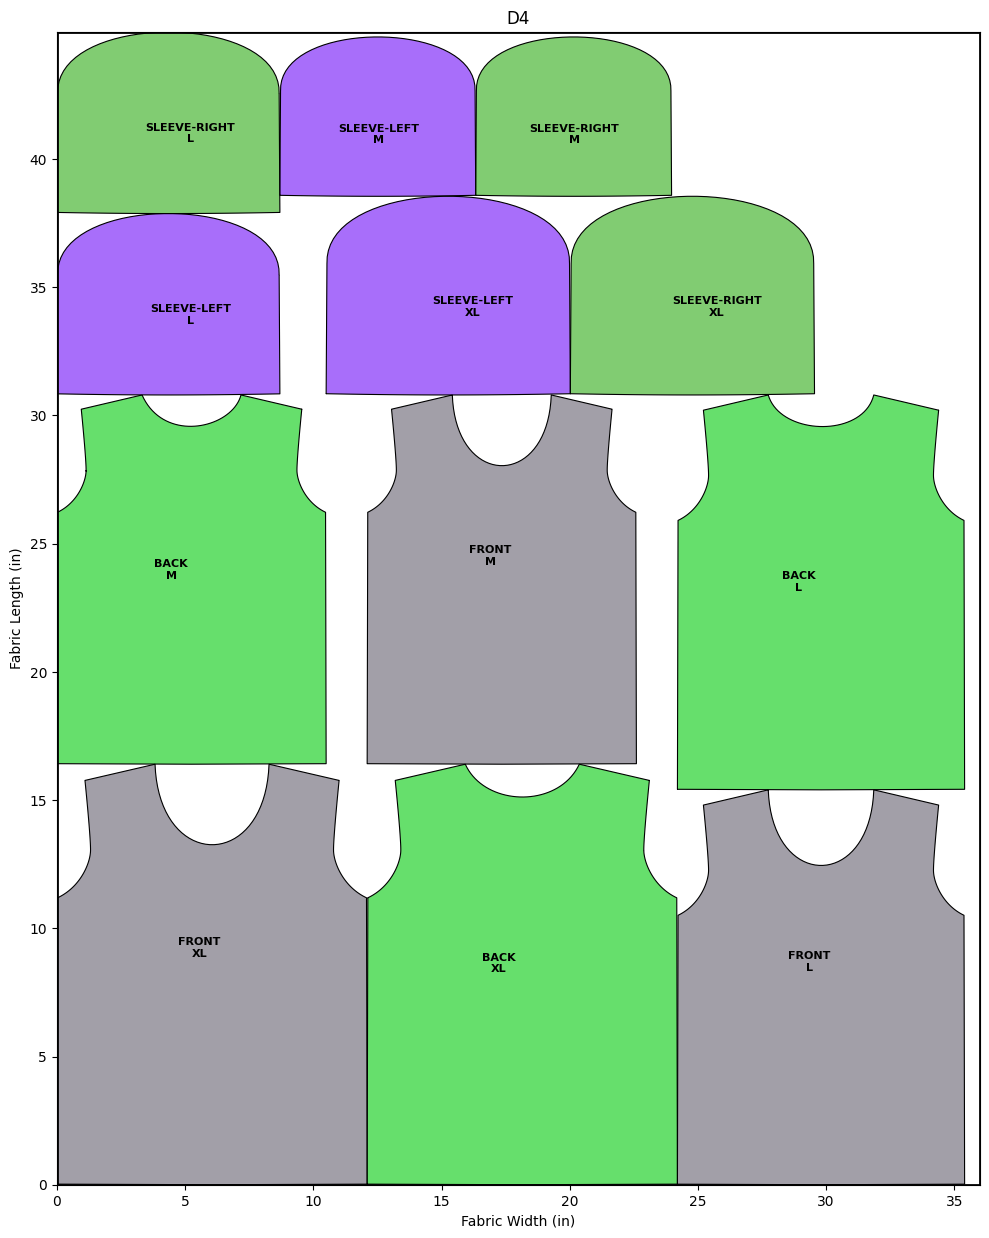

In [76]:
render_marker(
    placed_d4,
    strip_width=STRIP_WIDTH,
    title="D4",
    save_path="JK-123/D2.png"
)

In [32]:
base = ShapelyPolygon([
    (0, 0),
    (10, 0),
    (10, 4),
    (0, 4)
])

falling = ShapelyPolygon([
    (0, 0),
    (6, 0),
    (6, 3),
    (0, 3)
])

In [45]:
ShapelyPolygon(shapes[0]).bounds

ValueError: could not convert string to float: 'p'

In [34]:
final = drop_until_collision(
    poly=falling,
    placed_polys=placed,
    y_start=20.0,
    step=0.1
)

print(final.bounds)


(0.0, 4.099999999999987, 6.0, 7.099999999999987)


In [35]:
final.bounds

(0.0, 4.099999999999987, 6.0, 7.099999999999987)